# 3 AutoEncoders

In [1]:
# Imports necessary libraries and performs folder cleanup.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
from PIL import Image
from tqdm import tqdm
import time
import os
import shutil
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_recall_curve, f1_score, precision_score, recall_score, accuracy_score
import glob

# Use the specified output path
artifacts_dir = 'runs-q3'
if os.path.exists(artifacts_dir):
    print(f"Removing old artifacts directory: {artifacts_dir}")
    shutil.rmtree(artifacts_dir)
print(f"Creating clean artifacts directory: {artifacts_dir}")
os.makedirs(artifacts_dir)

# Fix seed for reproducible randomization.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)
np.random.seed(seed)

# Set plotting theme and helper functions.
sns.set_theme(context="paper", style="darkgrid", palette="magma", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    """Adds standard info and styling to a Matplotlib plot."""
    plt.text(0.95, 0.95, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.tight_layout()

Removing old artifacts directory: runs-q3
Creating clean artifacts directory: runs-q3
Seed generated: 1027714457


### Model Import

In [2]:
class Linear:
    def __init__(self, input_dim, output_dim, activation):
        self.activation = activation()
        self.biases = np.zeros((output_dim, 1))
        # Weight initialization
        scale = np.sqrt(2. / input_dim) if activation.__name__ == "ReLU" else np.sqrt(1. / input_dim)
        self.weights = rng.standard_normal(size=(output_dim, input_dim)) * scale
        self.grad_weights = np.zeros_like(self.weights)
        self.grad_biases = np.zeros_like(self.biases)
        # Adam optimizer state
        self.m_weights, self.v_weights = np.zeros_like(self.weights), np.zeros_like(self.weights)
        self.m_biases, self.v_biases = np.zeros_like(self.biases), np.zeros_like(self.biases)

    def forward(self, x):
        self.input = x
        self.z = np.dot(self.weights, self.input) + self.biases
        self.output = self.activation.forward(self.z)
        return self.output

    def backward(self, grad_output):
        grad_z = self.activation.backward(grad_output)
        batch_size = self.input.shape[1]
        # Average gradients over the batch
        grad_w = np.dot(grad_z, self.input.T) / batch_size
        grad_b = np.sum(grad_z, axis=1, keepdims=True) / batch_size
        self.grad_weights += grad_w
        self.grad_biases += grad_b
        grad_input = np.dot(self.weights.T, grad_z)
        return grad_input

class ReLU:
    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

class Sigmoid:
    def forward(self, x):
        x = np.clip(x, -500, 500)
        self.output = 1 / (1 + np.exp(-x))
        return self.output
    def backward(self, grad_output):
        return grad_output * self.output * (1 - self.output)

def mse_loss(y_pred, y_true):
    loss = np.mean((y_pred - y_true)**2)
    grad = 2 * (y_pred - y_true) / y_true.shape[1]  # Normalize by batch size
    return loss, grad

class Model:
    def __init__(self, layers, loss_fn='mse'):
        self.layers = layers
        self.loss_function = mse_loss
        self.t = 0
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x
    def backward(self, grad):
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
    def train(self, x, y):
        y_pred = self.forward(x)
        loss, grad_loss = self.loss_function(y_pred, y)
        self.backward(grad_loss)
        return loss
    def zero_grad(self):
        for layer in self.layers:
            layer.grad_weights.fill(0)
            layer.grad_biases.fill(0)
    def update(self, learning_rate, beta1=0.9, beta2=0.999, epsilon=1e-8):
        self.t += 1
        for layer in self.layers:
            layer.m_weights = beta1 * layer.m_weights + (1 - beta1) * layer.grad_weights
            layer.m_biases = beta1 * layer.m_biases + (1 - beta1) * layer.grad_biases
            layer.v_weights = beta2 * layer.v_weights + (1 - beta2) * (layer.grad_weights**2)
            layer.v_biases = beta2 * layer.v_biases + (1 - beta2) * (layer.grad_biases**2)
            m_hat_w = layer.m_weights / (1 - beta1**self.t)
            m_hat_b = layer.m_biases / (1 - beta1**self.t)
            v_hat_w = layer.v_weights / (1 - beta2**self.t)
            v_hat_b = layer.v_biases / (1 - beta2**self.t)
            layer.weights -= learning_rate * m_hat_w / (np.sqrt(v_hat_w) + epsilon)
            layer.biases -= learning_rate * m_hat_b / (np.sqrt(v_hat_b) + epsilon)
        self.zero_grad()
    def predict(self, x):
        return self.forward(x.T).T

## Autoencoder for Image Reconstruction

### Autoencoder Implementation

In [3]:
class MLPAutoencoder:
    def __init__(self, input_dim, bottleneck_dim, base_hidden_dim):
        self.input_dim = input_dim
        self.bottleneck_dim = bottleneck_dim
        self.base_hidden_dim = base_hidden_dim
        
        encoder_hidden_dims = [base_hidden_dim, base_hidden_dim // 2,
            base_hidden_dim // 4, base_hidden_dim // 8
        ]
        layers = []
        current_dim = input_dim
        for h_dim in encoder_hidden_dims:
            layers.append(Linear(current_dim, h_dim, ReLU))
            current_dim = h_dim
        layers.append(Linear(current_dim, bottleneck_dim, ReLU))
        current_dim = bottleneck_dim
        for h_dim in reversed(encoder_hidden_dims):
            layers.append(Linear(current_dim, h_dim, ReLU))
            current_dim = h_dim
        layers.append(Linear(current_dim, input_dim, Sigmoid))
        
        self.model = Model(layers, loss_fn='mse')
        

    def train(self, X_train, epochs, batch_size, learning_rate,
                patience=10, relative_loss_threshold=0.01):
            print(f"\nTraining Autoencoder with bottleneck dimension: {self.bottleneck_dim}")
            num_samples = X_train.shape[0]
            epoch_losses = []  

            for epoch in range(epochs):
                permutation = rng.permutation(num_samples)
                X_shuffled = X_train[permutation]
                pbar = tqdm(range(0, num_samples, batch_size), desc=f"Epoch {epoch+1}/{epochs}")
                total_epoch_loss = 0

                for i in pbar:
                    X_batch = X_shuffled[i:i+batch_size]
                    # Perform a forward pass, calculate MSE loss, and backpropagate
                    loss = self.model.train(X_batch.T, X_batch.T)
                    # Update the model's parameters
                    self.model.update(learning_rate)
                    total_epoch_loss += loss * len(X_batch)
                    pbar.set_postfix({'loss': f'{loss:.6f}'})

                avg_epoch_loss = total_epoch_loss / num_samples
                epoch_losses.append(avg_epoch_loss)

                if epoch >= patience:
                    # Get the loss from 'patience' epochs ago
                    past_loss = epoch_losses[epoch - patience]
                    
                    # Stop if L_t >= (1 - threshold) * L_{t-patience} 
                    if avg_epoch_loss >= (1 - relative_loss_threshold) * past_loss:
                        print(f"\nEarly stopping triggered at epoch {epoch + 1}.")
                        print(f"Loss ({avg_epoch_loss:.6f}) did not improve by more than {relative_loss_threshold*100}% from epoch {epoch + 1 - patience}'s loss ({past_loss:.6f}).")
                        break

    def predict(self, X_test):
        return self.model.predict(X_test)

Loading MNIST dataset.
MNIST data loaded: 59500 train, 10500 test samples.

Training Autoencoder with bottleneck dimension: 32


Epoch 10/10: 100%|██████████| 465/465 [00:04<00:00, 100.66it/s, loss=0.039143]



Visualizing original vs. reconstructed digits.


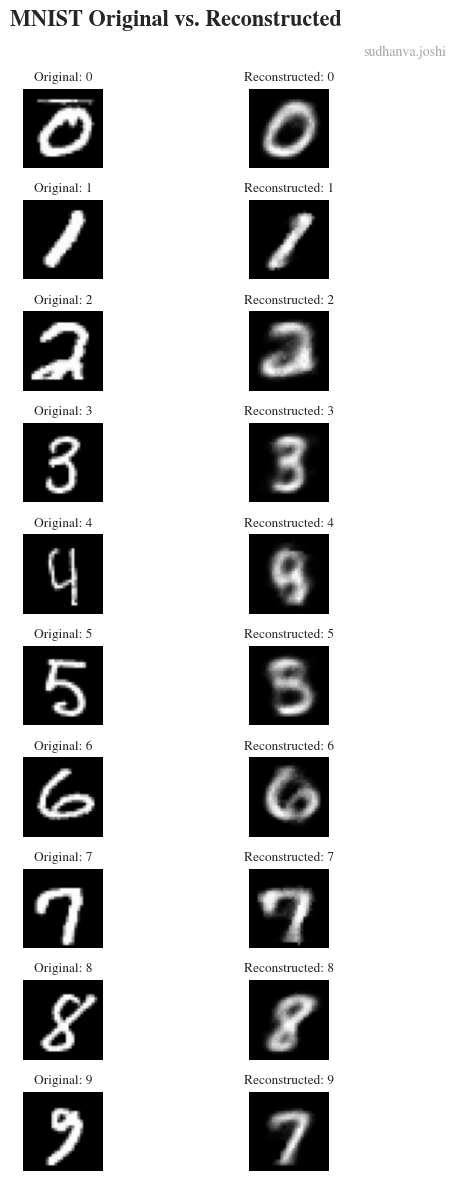

In [4]:
print("Loading MNIST dataset.")
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
X, y = X / 255.0, y.astype(int) # Normalize and cast labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=seed)
print(f"MNIST data loaded: {X_train.shape[0]} train, {X_test.shape[0]} test samples.")

autoencoder = MLPAutoencoder(input_dim=X_train.shape[1], bottleneck_dim=32, base_hidden_dim=64)
autoencoder.train(X_train, epochs=10, batch_size=128, learning_rate=1e-3)


print("\nVisualizing original vs. reconstructed digits.")
reconstructions = autoencoder.predict(X_test)

fig, axes = plt.subplots(nrows=10, ncols=2, figsize=(6, 12))

fig.suptitle("MNIST Original vs. Reconstructed", fontsize=16, fontweight='bold')

for i in range(10):
    # Find the index of the first occurrence of digit 'i' in the test set
    idx = np.where(y_test == i)[0][0]
    
    # Plot Original Image
    ax_orig = axes[i, 0]
    ax_orig.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax_orig.set_title(f"Original: {i}")
    ax_orig.axis('off')
    
    # Plot Reconstructed Image
    ax_recon = axes[i, 1]
    ax_recon.imshow(reconstructions[idx].reshape(28, 28), cmap='gray')
    ax_recon.set_title(f"Reconstructed: {i}")
    ax_recon.axis('off')

fig.text(0.95, 0.95, username, ha="right", va="top",
         fontsize=10, color="gray", alpha=0.7)

fig.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(os.path.join(artifacts_dir, 'mnist_recon.png'))
plt.show()

## 3.2 Anomaly Detection with Autoencoder

- MNIST Reconstruction

This plot confirms our autoencoder works. It successfully compresses and reconstructs the simple MNIST digits, with the expected loss of sharpness due to information compression.

- ROC Curves

This plot measures anomaly detection performance. The AUC scores of ~0.71 show the model is only moderately better than random guessing at distinguishing "normal" faces from "anomalies."

- Classification Examples

This plot reveals the model's primary failure. All reconstructions are the same blurry, "average face," proving the model couldn't handle the high-resolution image data and collapsed to a generic output.

- Precision-Recall (PR) Curve

This plot shows the model's reliability. It can be very precise (correctly flagging anomalies) only when it finds very few of them (low recall). As it tries to find more anomalies, its accuracy plummets.

In [5]:
def load_lfw_from_folder(data_path, min_faces_per_person=20, resize_factor=0.5):
    orig_h, orig_w = 250, 250
    crop_h, crop_w = 125, 125 # A reasonable central crop
    
    target_h = int(crop_h * resize_factor)
    target_w = int(crop_w * resize_factor)

    person_paths = [d.path for d in os.scandir(data_path) if d.is_dir()]
    person_counts = {}
    for person_path in person_paths:
        person_name = os.path.basename(person_path)
        image_files = [f for f in os.listdir(person_path) if f.endswith('.jpg')]
        if len(image_files) >= min_faces_per_person:
            person_counts[person_name] = image_files

    print(f"Found {len(person_counts)} people with at least {min_faces_per_person} images.")

    X_data, y_data = [], []
    target_names = sorted(person_counts.keys())
    name_to_label = {name: i for i, name in enumerate(target_names)}

    for person_name, image_files in person_counts.items():
        person_path = os.path.join(data_path, person_name)
        label = name_to_label[person_name]
        for image_file in image_files:
            image_path = os.path.join(person_path, image_file)
            with Image.open(image_path) as img:
                # Crop to center
                left = (orig_w - crop_w) // 2
                top = (orig_h - crop_h) // 2
                right = (orig_w + crop_w) // 2
                bottom = (orig_h + crop_h) // 2
                img = img.crop((left, top, right, bottom))
                
                # Convert to grayscale, resize, and flatten
                img = img.convert('L').resize((target_w, target_h))
                X_data.append(np.array(img).flatten())
                y_data.append(label)

    X = np.array(X_data)
    y = np.array(y_data)
    
    return X, y, target_names, target_h, target_w



def evaluate_anomaly_detection(autoencoder, X_test, y_test):
    """
    Calculates reconstruction errors and anomaly detection metrics, including accuracy.
    """
    reconstructions = autoencoder.predict(X_test)
    errors = np.mean((X_test - reconstructions)**2, axis=1)

    # Determine the best threshold by maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, errors)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_threshold = thresholds[np.argmax(f1_scores)]
    y_pred = (errors > best_threshold).astype(int)

    fpr, tpr, _ = roc_curve(y_test, errors)
    return {
        'accuracy': accuracy_score(y_test, y_pred),
        'auc': auc(fpr, tpr),
        'f1': f1_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'threshold': best_threshold,
        'errors': errors, 'labels': y_test, 'roc_curve': (fpr, tpr)
    }

Loading LFW dataset from local folder: ./data/Q3/LFW_Dataset
Found 62 people with at least 20 images.
Dataset loaded: 3023 samples, 125x125 images.

Training set size (normal only): 424
Test set size: 2599 (106 normal, 2493 anomaly)

Training Autoencoder with bottleneck dimension: 32


Epoch 50/50: 100%|██████████| 7/7 [00:03<00:00,  1.80it/s, loss=0.019100]



Results for bottleneck_dim=32: AUC=0.6992, F1=0.9790

Training Autoencoder with bottleneck dimension: 64


Epoch 50/50: 100%|██████████| 7/7 [00:03<00:00,  1.78it/s, loss=0.016590]



Results for bottleneck_dim=64: AUC=0.6907, F1=0.9790

Training Autoencoder with bottleneck dimension: 128


Epoch 50/50: 100%|██████████| 7/7 [00:03<00:00,  1.82it/s, loss=0.018291]



Results for bottleneck_dim=128: AUC=0.6920, F1=0.9790


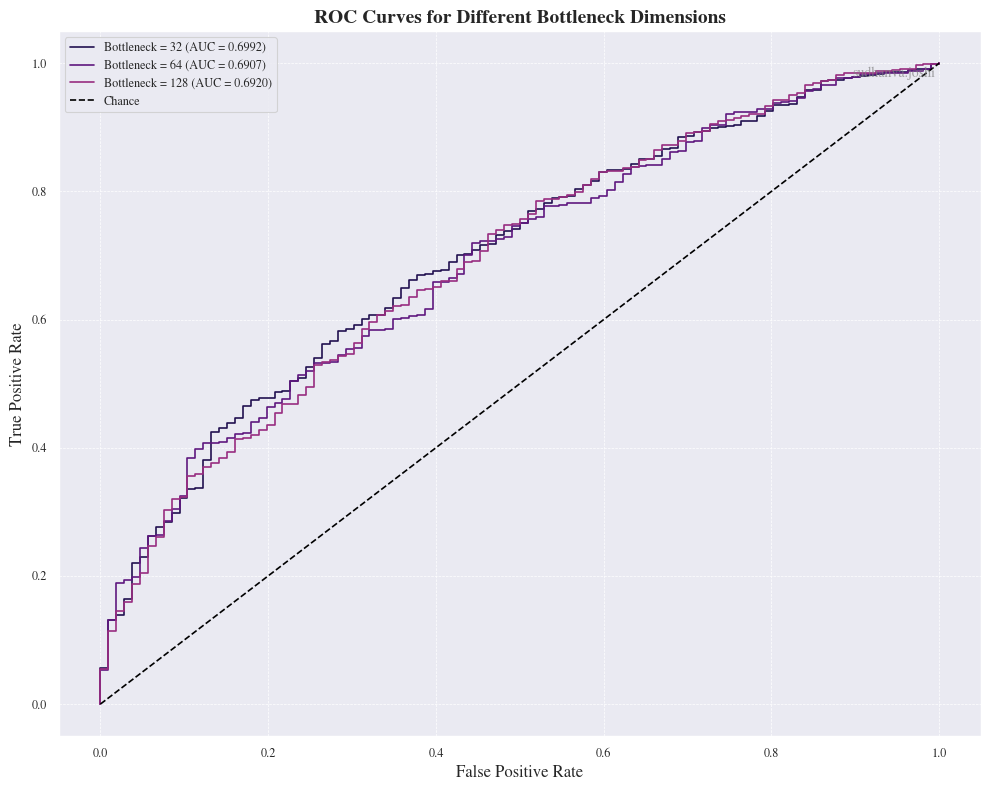


 Best model has bottleneck dimension: 32 with AUC: 0.6992


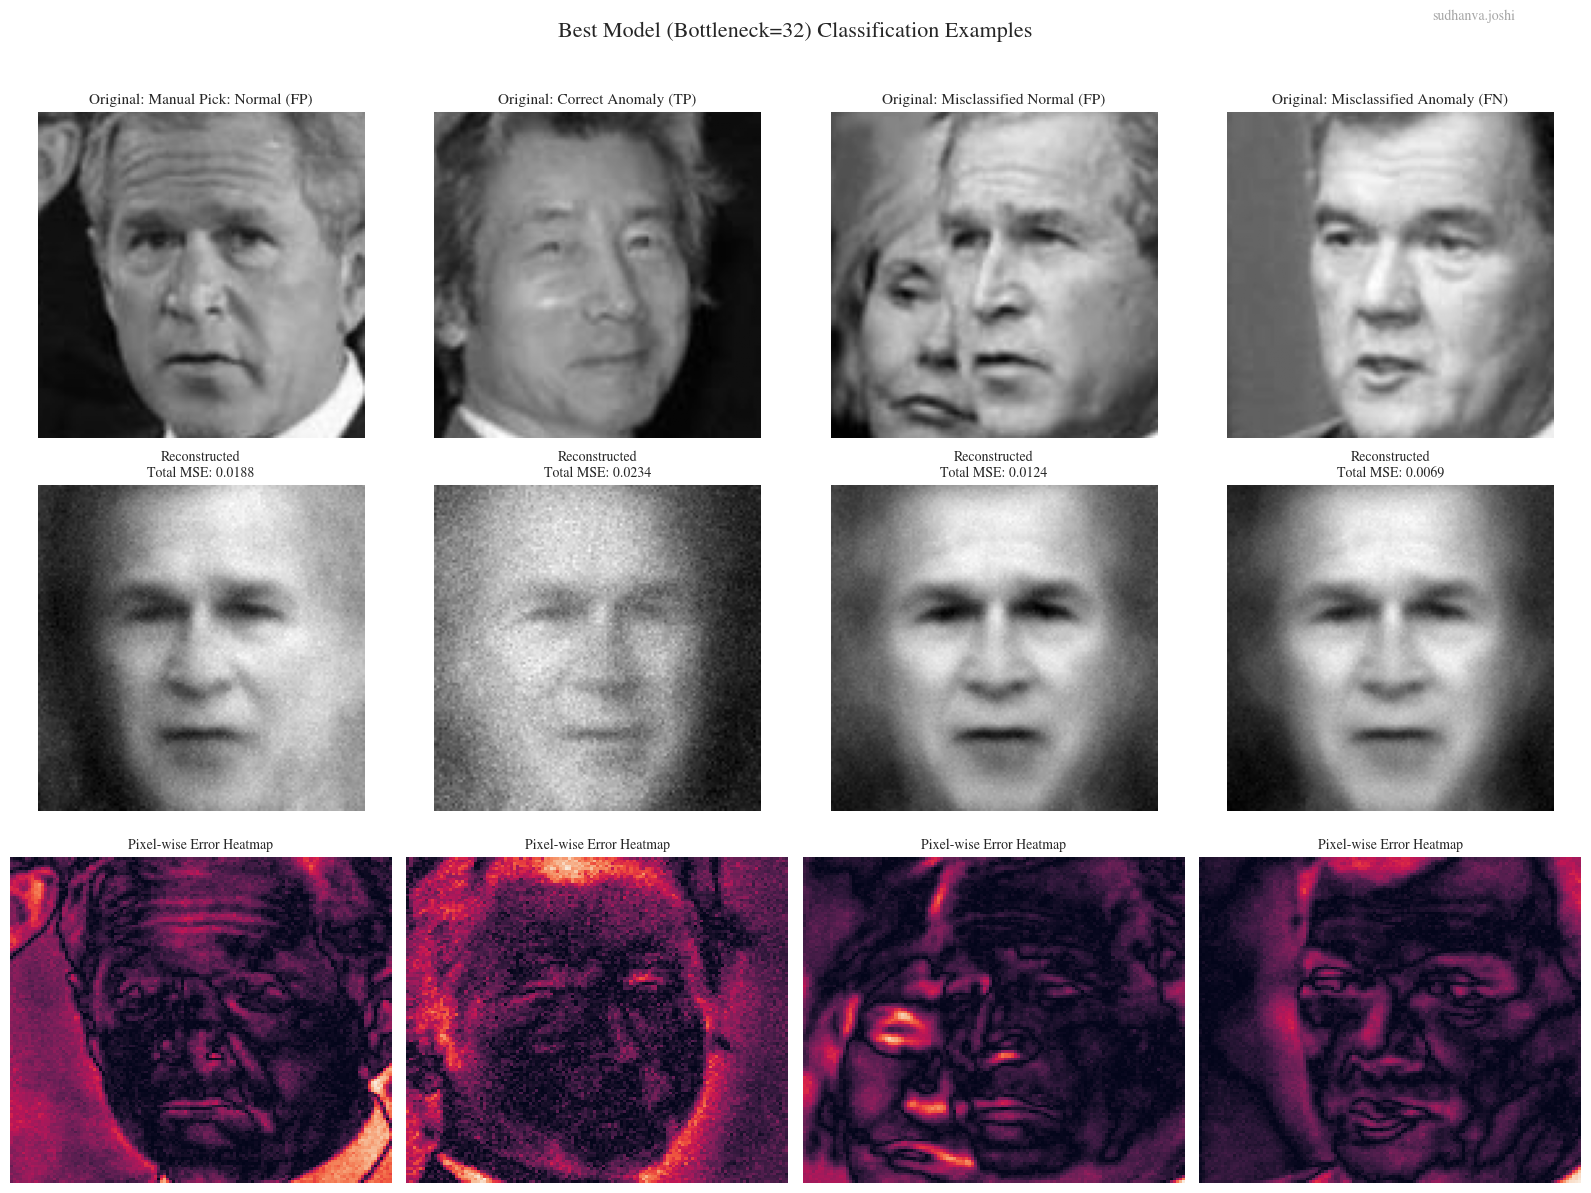

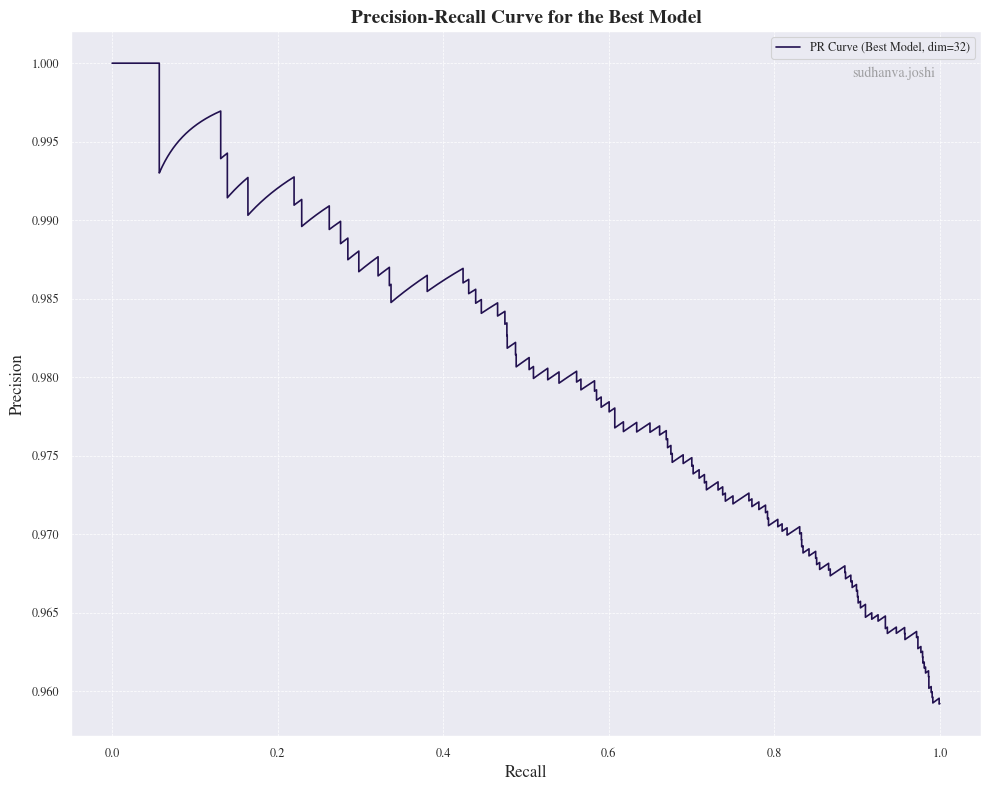

In [6]:
DATA_PATH = './data/Q3/LFW_Dataset'
print(f"Loading LFW dataset from local folder: {DATA_PATH}")

X, y, target_names, h, w = load_lfw_from_folder(DATA_PATH, min_faces_per_person=20, resize_factor=1)
input_dim = h * w
print(f"Dataset loaded: {X.shape[0]} samples, {h}x{w} images.")
george_bush_class_id = target_names.index('George_W_Bush')

X_normal = X[y == george_bush_class_id]
X_anomaly = X[y != george_bush_class_id]
X_train_normal, X_test_normal = train_test_split(X_normal, test_size=0.2, random_state=seed)
X_test = np.concatenate([X_test_normal, X_anomaly], axis=0)
y_test = np.concatenate([np.zeros(len(X_test_normal)), np.ones(len(X_anomaly))])
X_train_normal, X_test = X_train_normal / 255.0, X_test / 255.0
print(f"\nTraining set size (normal only): {len(X_train_normal)}")
print(f"Test set size: {len(X_test)} ({len(X_test_normal)} normal, {len(X_anomaly)} anomaly)")

bottleneck_dims = [32, 64, 128]

results = {}
plt.figure(figsize=(10, 8))
for dim in bottleneck_dims:
    autoencoder = MLPAutoencoder(input_dim, bottleneck_dim=dim, base_hidden_dim=512)
    autoencoder.train(X_train_normal, epochs=50, batch_size=64, learning_rate=1e-4)
    metrics = evaluate_anomaly_detection(autoencoder, X_test, y_test)
    results[dim] = {'model': autoencoder, 'metrics': metrics}
    print(f"\nResults for bottleneck_dim={dim}: AUC={metrics['auc']:.4f}, F1={metrics['f1']:.4f}")
    fpr, tpr = metrics['roc_curve']
    plt.plot(fpr, tpr, label=f'Bottleneck = {dim} (AUC = {metrics["auc"]:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plotinfo('ROC Curves for Different Bottleneck Dimensions', 'False Positive Rate', 'True Positive Rate')
plt.legend()
plt.savefig(os.path.join(artifacts_dir, 'roc_curves.png'))
plt.show()

best_dim = max(results, key=lambda d: results[d]['metrics']['auc'])
best_model, best_metrics = results[best_dim]['model'], results[best_dim]['metrics']
print(f"\n Best model has bottleneck dimension: {best_dim} with AUC: {best_metrics['auc']:.4f}")

def visualize_classifications(model, X_test, metrics, h, w, best_dim, userid=username):
    """
    Visualizes one example from each classification case (TN, TP, FP, FN),
    manually picking a substitute if a category is empty.
    """
    errors, threshold, true_labels = metrics['errors'], metrics['threshold'], metrics['labels']
    predictions = (errors > threshold).astype(int)

    # Find indices for each classification type
    indices = {
        'Correct Normal (TN)': np.where((predictions == 0) & (true_labels == 0))[0],
        'Correct Anomaly (TP)': np.where((predictions == 1) & (true_labels == 1))[0],
        'Misclassified Normal (FP)': np.where((predictions == 1) & (true_labels == 0))[0],
        'Misclassified Anomaly (FN)': np.where((predictions == 0) & (true_labels == 1))[0]
    }

    display_samples = {}
    
    # Case 1: True Negative (Normal, predicted as Normal)
    if len(indices['Correct Normal (TN)']) > 0:
        display_samples['TN'] = (rng.choice(indices['Correct Normal (TN)']), 'Correct Normal (TN)')
    else: # Fallback: if no TN, show a normal sample it got wrong (an FP)
        display_samples['TN'] = (rng.choice(indices['Misclassified Normal (FP)']), 'Manual Pick: Normal (FP)')

    # Case 2: True Positive (Anomaly, predicted as Anomaly)
    if len(indices['Correct Anomaly (TP)']) > 0:
        display_samples['TP'] = (rng.choice(indices['Correct Anomaly (TP)']), 'Correct Anomaly (TP)')
    else: # Fallback: if no TP, show an anomaly it got wrong (an FN)
        display_samples['TP'] = (rng.choice(indices['Misclassified Anomaly (FN)']), 'Manual Pick: Anomaly (FN)')
        
    # Case 3: False Positive (Normal, predicted as Anomaly)
    if len(indices['Misclassified Normal (FP)']) > 0:
        display_samples['FP'] = (rng.choice(indices['Misclassified Normal (FP)']), 'Misclassified Normal (FP)')
    else: # Fallback: if no FP, show a normal sample it got right (a TN)
        display_samples['FP'] = (rng.choice(indices['Correct Normal (TN)']), 'Manual Pick: Normal (TN)')

    # Case 4: False Negative (Anomaly, predicted as Normal)
    if len(indices['Misclassified Anomaly (FN)']) > 0:
        display_samples['FN'] = (rng.choice(indices['Misclassified Anomaly (FN)']), 'Misclassified Anomaly (FN)')
    else:
        display_samples['FN'] = (rng.choice(indices['Correct Anomaly (TP)']), 'Manual Pick: Anomaly (TP)')

    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    fig.suptitle(f'Best Model (Bottleneck={best_dim}) Classification Examples', fontsize=16)
    reconstructions = model.predict(X_test)

    plot_map = {'TN': 0, 'TP': 1, 'FP': 2, 'FN': 3}
    for case, (sample_idx, display_title) in display_samples.items():
        col = plot_map[case]
        ax_orig, ax_recon, ax_heatmap = axes[0, col], axes[1, col], axes[2, col]
        
        original_img = X_test[sample_idx]
        reconstructed_img = reconstructions[sample_idx]

        # Plot Original, Reconstructed, and Heatmap
        ax_orig.imshow(original_img.reshape(h, w), cmap='gray')
        ax_orig.set_title(f"Original: {display_title}", fontsize=11)

        ax_recon.imshow(reconstructed_img.reshape(h, w), cmap='gray')
        ax_recon.set_title(f"Reconstructed\nTotal MSE: {errors[sample_idx]:.4f}", fontsize=10)

        error_map = np.abs(original_img - reconstructed_img).reshape(h, w)
        sns.heatmap(error_map, ax=ax_heatmap, cbar=False)
        ax_heatmap.set_title("Pixel-wise Error Heatmap", fontsize=10)
        
        ax_orig.axis('off'); ax_recon.axis('off'); ax_heatmap.axis('off')

    fig.text(0.95, 0.99, userid, ha="right", va="top",
             fontsize=10, color="gray", alpha=0.7)
    
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(os.path.join(artifacts_dir, 'classification_examples_with_heatmap.png'))
    plt.show()


visualize_classifications(best_model, X_test, best_metrics, h, w, best_dim)

plt.figure(figsize=(10, 8))
precision, recall, _ = precision_recall_curve(best_metrics['labels'], best_metrics['errors'])
plt.plot(recall, precision, label=f'PR Curve (Best Model, dim={best_dim})')
plotinfo('Precision-Recall Curve for the Best Model', 'Recall', 'Precision')
plt.legend()
plt.savefig(os.path.join(artifacts_dir, 'pr_curve.png'))
plt.show()